In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
import torch

from rl4co.envs import CVRPEnv
from rl4co.models.zoo.decomposition import DECOMP, KmeansPol, BaryCenterDecomp, Delegate
from rl4co.models.zoo.am import AttentionModelPolicy

In [15]:
torch.manual_seed(42)

env = CVRPEnv(generator_params={'num_loc': 60})
model = DECOMP(env,
                baseline='rollout',
                train_data_size=1_000,
                val_data_size=100)

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'env' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['env'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'policy' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['policy'])`.


In [4]:
decomp_pol = BaryCenterDecomp(4)
naive_pol = AttentionModelPolicy(env_name=env.name)

In [5]:
td = env.reset(batch_size=[4])
out_naive = naive_pol(td, env, return_actions=True)

In [10]:
display(out_naive["reward"])

tensor([-51.1249, -55.1938, -59.7577, -31.1812])

In [11]:
td = env.reset(batch_size=[4])

decomp_pol = BaryCenterDecomp(4)
out = decomp_pol(td, env, 3)

In [13]:
display(out["reward"])

tensor([-108.1331,  -69.3373,  -52.8091,  -44.2893])

In [18]:
def render_all(td, out, env):
    for state, actions in zip(td, out['actions'].cpu()):
        env.render(state, actions)

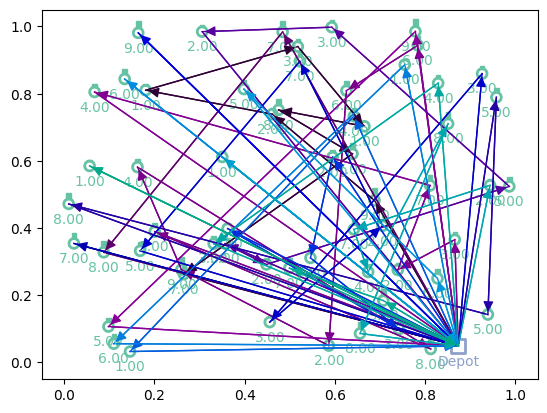

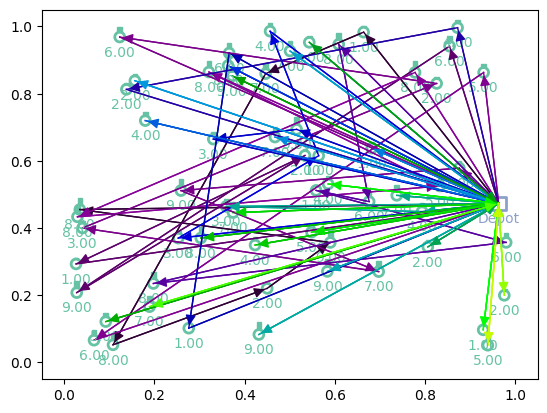

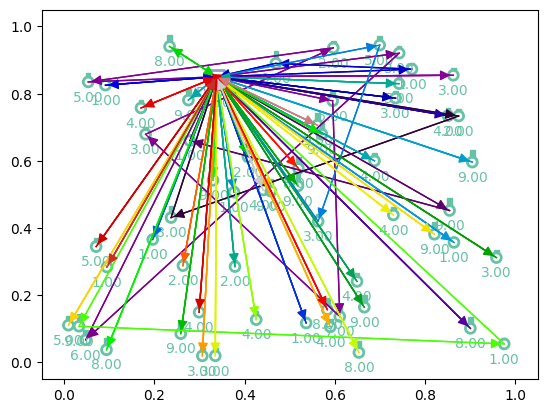

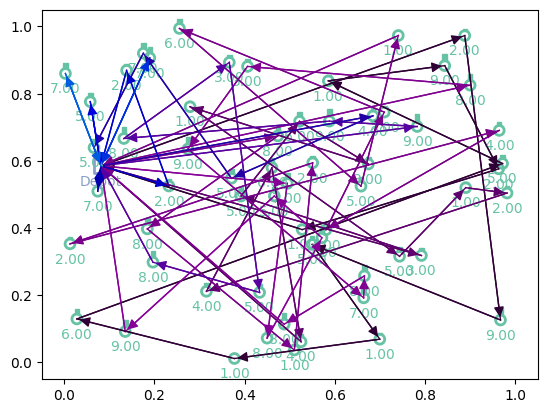

In [8]:
render_all(td, out_naive, env)

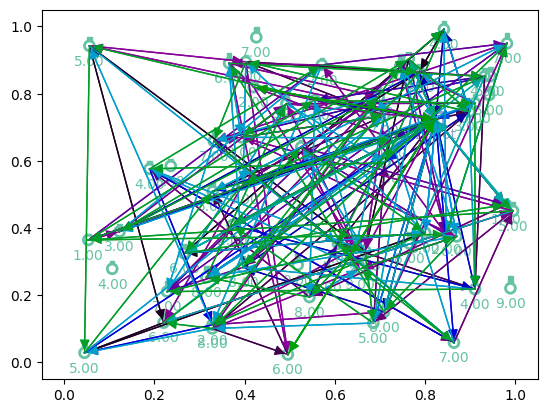

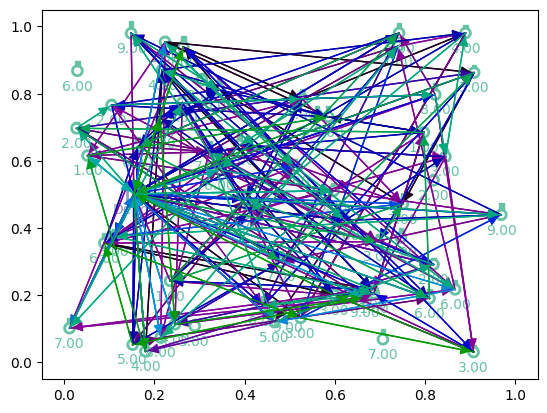

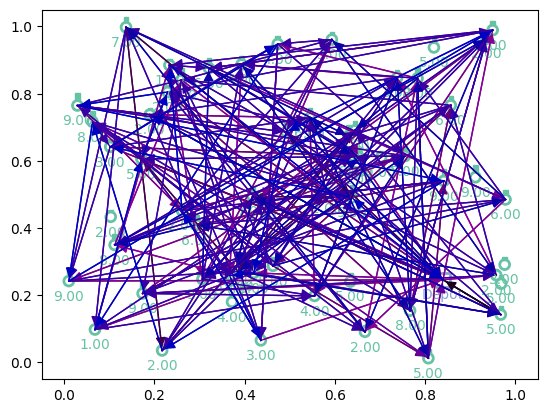

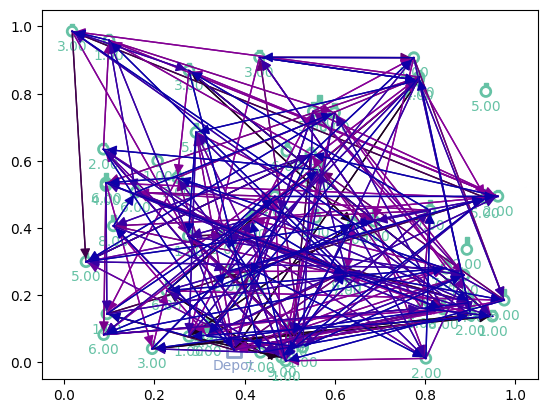

In [12]:
render_all(td, out, env)

In [20]:
env = CVRPEnv(generator_params={'num_loc': 10})
model = DECOMP(env,
                baseline='rollout',
                train_data_size=1_000,
                val_data_size=100,
                decomp_policy_kwargs={"num_subproblems": 2})

td = env.reset(batch_size=[2])
its = 2

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'env' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['env'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'policy' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['policy'])`.


In [22]:
td_base = td.copy()
# Generate initial solution using our naive policy
model = model.policy
sol = model.naive_policy(td, env, return_actions=True)

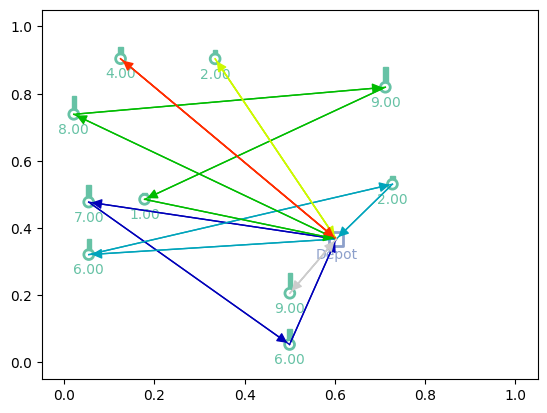

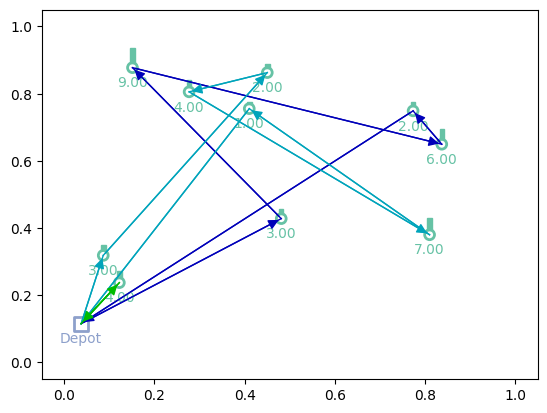

In [25]:
render_all(td, sol, env)

In [27]:
# Iterative loop to improve our solution
for _ in range(its):
    # Decompose our state td and sol tensor into its k subproblems
    # Returned td is reset to prepare for policy
    td = model.decompose(td, env, sol)
    td = env.reset(td)
    # Apply our constructive policy to each subproblem using parallelization
    sol = model.policy(td, env, return_actions=True)
    # Recompose our decomposed state and solution to the original problem sizes
    # To save complexity at the cost of some memory, we use our cached state td
    sol = model.recompose(td, sol)
    td = td_base.copy()

ValueError: n_samples=1 should be >= n_clusters=2.